[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_mst/BA_L7_mst.ipynb)

# BA_L7_mst: Correlation matrix and minimum spanning tree of 19 coins

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Pearson correlation matrix of daily log returns of 19 cryptocurrencies (EODHD, January 2021 - October 2026) and the minimum spanning tree (MST) built on the Mantegna distance d = sqrt(2(1 - rho)); node size grows with the MST degree.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['networkx']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [5]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Data

Daily closes of 19 coins from EODHD (course repository, `data/market`), 1 January 2021 to 23 October 2026.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [6]:
COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()           # daily log returns in %
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


### Method

Each coin is a node. Mantegna (1999) turns the Pearson correlation $\rho_{ij}$ of two coins into a metric distance

$$ d_{ij} = \sqrt{2\,(1 - \rho_{ij})}, \qquad \rho = 1 \Rightarrow d = 0, \quad \rho = 0 \Rightarrow d = \sqrt2 . $$

The **minimum spanning tree (MST)** is the set of $N - 1$ edges that connects all $N$ coins with the smallest total distance,
$\mathrm{MST} = \arg\min_{T} \sum_{(i,j) \in T} d_{ij}$. It keeps the strongest links; a **hub** is a coin with many MST edges (a high **degree**).

In [7]:
from scipy.sparse.csgraph import minimum_spanning_tree
import networkx as nx

C = R.corr()
iu = np.triu_indices(len(COINS), 1)
Dm = np.sqrt(2 * (1 - C.values))                         # Mantegna distance
mst = minimum_spanning_tree(np.triu(Dm, 1)).toarray()
G = nx.Graph()
for i, a in enumerate(COINS):
    for j, b in enumerate(COINS):
        if mst[i, j] > 0:
            G.add_edge(a, b, d=mst[i, j], rho=C.iloc[i, j])
deg = dict(G.degree())

pairs = C.where(np.triu(np.ones(C.shape, bool), 1)).stack()
cb = C['BTC'].drop('BTC')
print(f'Mean pairwise correlation (171 pairs): {C.values[iu].mean():.3f}')
print(f'Lowest pairwise correlation: {pairs.min():.3f} ({pairs.idxmin()[0]}-{pairs.idxmin()[1]})')
print(f'Correlation with BTC: lowest {cb.min():.3f} ({cb.idxmin()}), highest {cb.max():.3f} ({cb.idxmax()})')
for a, b in [('BTC', 'ETH'), ('DOGE', 'TRX')]:
    print(f'Worked example {a}-{b}: correlation {C.loc[a, b]:.3f}, distance d = {np.sqrt(2 * (1 - C.loc[a, b])):.3f}')
print('\nHubs: MST neighbours of the coins with the highest degree')
for n in sorted(deg, key=lambda k: -deg[k])[:3]:
    print(f'  {n}: degree {deg[n]} ({", ".join(sorted(G.neighbors(n)))})')
print(f'  BTC: degree {deg["BTC"]} ({", ".join(sorted(G.neighbors("BTC")))})')

Mean pairwise correlation (171 pairs): 0.597
Lowest pairwise correlation: 0.349 (DOGE-TRX)
Correlation with BTC: lowest 0.521 (TRX), highest 0.823 (ETH)
Worked example BTC-ETH: correlation 0.823, distance d = 0.595
Worked example DOGE-TRX: correlation 0.349, distance d = 1.141

Hubs: MST neighbours of the coins with the highest degree
  ETH: degree 6 (BNB, BTC, ETC, LINK, LTC, SOL)
  DOT: degree 6 (ADA, ALGO, ATOM, FIL, LINK, TRX)
  ETC: degree 3 (BCH, DOGE, ETH)
  BTC: degree 2 (ETH, XMR)


### The chart

Left: the correlation matrix (red = high correlation). Right: the MST; node size grows with the MST degree, edge width with the correlation.

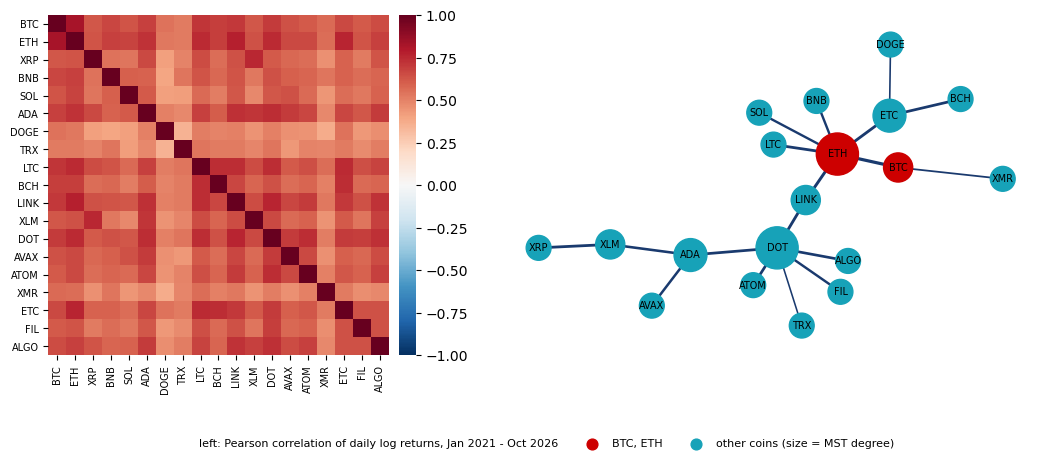

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1, 1.05]})
im = ax[0].imshow(C.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax[0].set_xticks(range(len(COINS))); ax[0].set_xticklabels(COINS, rotation=90, fontsize=7)
ax[0].set_yticks(range(len(COINS))); ax[0].set_yticklabels(COINS, fontsize=7)
for sp in ax[0].spines.values():
    sp.set_visible(False)
cbar = fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.02); cbar.outline.set_visible(False)
pos = nx.kamada_kawai_layout(G, weight='d')
nx.draw_networkx_edges(G, pos, ax=ax[1], edge_color=BLUE, width=[1 + 4 * (G[a][b]['rho'] - 0.5) for a, b in G.edges()])
nx.draw_networkx_nodes(G, pos, ax=ax[1], node_color=[RED if n in ('BTC', 'ETH') else TEAL for n in G.nodes()],
                       node_size=[200 + 120 * deg[n] for n in G.nodes()])
nx.draw_networkx_labels(G, pos, ax=ax[1], font_size=7)
ax[1].axis('off')
ax[1].scatter([], [], color=RED, s=60, label='BTC, ETH'); ax[1].scatter([], [], color=TEAL, s=60, label='other coins (size = MST degree)')
ax[0].plot([], [], color='none', label='left: Pearson correlation of daily log returns, Jan 2021 - Oct 2026')
slide_fig(fig, 'ba_l7_mst', 0.1, ncol=3)

**How to read it.** The mean pairwise correlation is high (about 0.6): coins move together. ETH and DOT are the hubs of the tree;
BTC sits at the edge of the tree, linked to ETH and XMR only.